**CS1090A Final Project · Group 77**

**Members:** Daniel Wang, Russell Luo, Tae Jun Cha, Aviel Eng, Eric Huang

# Milestone 2 — Data: Predicting Soccer Player Market Values

**Dataset:** [Transfermarkt "player-scores" (Kaggle, davidcariboo)](https://www.kaggle.com/datasets/davidcariboo/player-scores)

**This notebook does four things:**

1. **Load** every table in the dataset and record its size, keys and date range.
2. **Clean** the tables we need: types, missing values, impossible values, duplicates and broken keys.
3. **Build** one modeling table with **one row per player per season**: that season's performance and personal details, plus the market value at the end of the season.
4. **Restate the project question** precisely, based on what the data can actually support.

EDA and the baseline model are left for Milestone 3.

## 0. Setup

In [1]:
import os, glob, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Where the Kaggle CSVs live. Download archive.zip from Kaggle and either
#   (a) unzip it into ./data, or (b) point DATA_DIR at the folder / the zip.
DATA_DIR = Path(os.environ.get("DATA_DIR", "data"))

/Users/dwang/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
def find_data_dir(p: Path) -> Path:
    # Accept a folder of CSVs, a folder containing archive.zip, or the zip itself.
    if p.suffix == ".zip":
        out = p.with_suffix("")
        zipfile.ZipFile(p).extractall(out)
        p = out
    zips = list(p.glob("*.zip"))
    if not list(p.rglob("players.csv*")) and zips:
        zipfile.ZipFile(zips[0]).extractall(p)
    hits = list(p.rglob("players.csv*"))
    if not hits:
        # Last resort: download with kagglehub (needs internet; public dataset).
        import kagglehub
        return Path(kagglehub.dataset_download("davidcariboo/player-scores"))
    return hits[0].parent

DATA_DIR = find_data_dir(DATA_DIR)
print("Reading from:", DATA_DIR)
sorted(f.name for f in DATA_DIR.iterdir())

Reading from: data


['appearances.csv',
 'clubs.csv',
 'competitions.csv',
 'games.csv',
 'player_valuations.csv',
 'players.csv',
 'transfers.csv']

## 1. Load every table

The dataset is a small relational database scraped from Transfermarkt. We load all of it first so we can see what is there before deciding what to keep.

In [3]:
TABLES = ["players", "player_valuations", "appearances", "games", "clubs",
          "competitions", "transfers", "club_games", "game_events", "game_lineups"]

raw = {}
for t in TABLES:
    f = next(iter(DATA_DIR.glob(f"{t}.csv*")), None)
    if f is not None:
        raw[t] = pd.read_csv(f, low_memory=False)

def date_range(df):
    col = "date" if "date" in df else None
    if col is None:
        return ""
    d = pd.to_datetime(df[col], errors="coerce")
    return f"{d.min():%Y-%m-%d} → {d.max():%Y-%m-%d}"

inventory = pd.DataFrame({
    "rows": {t: len(d) for t, d in raw.items()},
    "columns": {t: d.shape[1] for t, d in raw.items()},
    "memory_MB": {t: d.memory_usage(deep=True).sum() / 1e6 for t, d in raw.items()},
    "date_range": {t: date_range(d) for t, d in raw.items()},
})
inventory

,rows,columns,memory_MB,date_range
players,50149,26,66.81,
player_valuations,656301,6,145.00,2000-01-20 → 2026-06-12
appearances,1894350,13,653.41,2012-07-03 → 2026-06-28
games,88958,23,99.75,2006-06-09 → 2026-07-06
clubs,796,17,0.59,
competitions,65,11,0.04,
transfers,175165,10,67.38,


### What each table is, and how they connect

| Table | Grain (one row is…) | Primary key | Joins to |
|---|---|---|---|
| `players` | a player (current snapshot) | `player_id` | clubs via `current_club_id` |
| `player_valuations` | one market-value estimate for a player on a date | (`player_id`, `date`) | players |
| `appearances` | one player's stat line in one game | `appearance_id` | players, games, clubs (`player_club_id`) |
| `games` | a match | `game_id` | clubs (home/away), competitions |
| `clubs` | a club (current snapshot) | `club_id` | competitions via `domestic_competition_id` |
| `competitions` | a league or cup | `competition_id` | — |
| `transfers` | a player moving between clubs | — | players, clubs |
| `club_games`, `game_events`, `game_lineups` | match-level detail | — | games |

For a market-value project the core is **`player_valuations` (the target)**, **`appearances` (performance)**, **`players` (personal details)**, and **`clubs` + `competitions` (which league the player was in)**. We use `games` only to assign each appearance to a season. The match-level tables and `transfers` aren't needed for this milestone.

**Important:** `players` and `clubs` are *current snapshots*. A player's `current_club_id` is his club *today*, not in 2016. To place a player in a league in a given season, we use the club he actually played for in his appearances that season.

In [4]:
for t in ["players", "player_valuations", "appearances", "games", "clubs", "competitions"]:
    print(f"\n=== {t} ===")
    display(raw[t].head(3))


=== players ===


,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,date_of_birth,sub_position,position,foot,height_in_cm,contract_expiration_date,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,1978-06-09 00:00:00,Centre-Forward,Attack,right,184.00,NaN,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,"1,000,000.00","30,000,000.00"
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,1980-08-06 00:00:00,Goalkeeper,Goalkeeper,left,190.00,NaN,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,"750,000.00","8,000,000.00"
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,1981-01-30 00:00:00,Centre-Forward,Attack,NaN,NaN,NaN,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,"1,000,000.00","34,500,000.00"



=== player_valuations ===


,player_id,date,market_value_in_eur,current_club_name,current_club_id,player_club_domestic_competition_id
0,405973,2000-01-20,150000,Unknown,3057,BE1
1,342216,2001-07-20,100000,Unknown,1241,SC1
2,3132,2003-12-09,400000,Dynamo Kyiv,126,TR1



=== appearances ===


,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45


... (2 outputs left out)


=== clubs ===


,club_id,club_code,name,domestic_competition_id,total_market_value,squad_size,average_age,foreigners_number,foreigners_percentage,national_team_players,stadium_name,stadium_seats,net_transfer_record,coach_name,last_season,filename,url
0,10,arminia-bielefeld,Arminia Bielefeld,L1,NaN,27,25.30,15,55.60,4,SchücoArena,26515,+€5.90m,NaN,2021,../data/raw/transfermarkt-scraper/2021/clubs.j...,https://www.transfermarkt.co.uk/arminia-bielef...
1,10004,paris-fc,Paris FC,FR1,NaN,27,27.20,14,51.90,7,Stade Jean Bouin,19904,€-25.00m,Stéphane Gilli,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/paris-fc/start...
2,10010,esporte-clube-bahia,Esporte Clube Bahia,BRA1,NaN,32,26.60,9,28.10,3,Arena Fonte Nova,47364,+€8.14m,NaN,2025,../data/raw/transfermarkt-scraper/2025/clubs.j...,https://www.transfermarkt.co.uk/esporte-clube-...



=== competitions ===


,competition_id,competition_code,name,sub_type,type,country_id,country_name,domestic_league_code,confederation,total_clubs,url
0,A1,bundesliga,bundesliga,first_tier,domestic_league,127,Austria,A1,europa,12.00,https://www.transfermarkt.co.uk/bundesliga/sta...
1,AFAC,afc-asian-cup,afc-asian-cup,afc_asian_cup,national_team_competition,-1,NaN,NaN,asien,NaN,https://www.transfermarkt.co.uk/afc-asian-cup/...
2,AFCN,africa-cup-of-nations,africa-cup-of-nations,africa_cup_of_nations,national_team_competition,-1,NaN,NaN,afrika,NaN,https://www.transfermarkt.co.uk/africa-cup-of-...


## 2. Check that the keys hold

Before cleaning, we confirm that primary keys are unique and foreign keys actually match. If they don't, joins silently drop or duplicate rows.

In [5]:
def key_report(df, cols, name):
    dup = df.duplicated(cols).sum()
    nulls = df[cols].isna().any(axis=1).sum()
    return {"table": name, "key": "+".join(cols), "rows": len(df), "duplicate_keys": dup, "null_keys": nulls}

def fk_report(child, col, parent, pcol, name):
    vals = child[col].dropna()
    missing = ~vals.isin(parent[pcol])
    return {"relation": name, "child_rows_with_key": len(vals),
            "unmatched": int(missing.sum()), "unmatched_pct": 100 * missing.mean()}

display(pd.DataFrame([
    key_report(raw["players"], ["player_id"], "players"),
    key_report(raw["player_valuations"], ["player_id", "date"], "player_valuations"),
    key_report(raw["appearances"], ["appearance_id"], "appearances"),
    key_report(raw["appearances"], ["player_id", "game_id"], "appearances"),
    key_report(raw["games"], ["game_id"], "games"),
    key_report(raw["clubs"], ["club_id"], "clubs"),
    key_report(raw["competitions"], ["competition_id"], "competitions"),
]))

pd.DataFrame([
    fk_report(raw["player_valuations"], "player_id", raw["players"], "player_id", "valuations → players"),
    fk_report(raw["appearances"], "player_id", raw["players"], "player_id", "appearances → players"),
    fk_report(raw["appearances"], "game_id", raw["games"], "game_id", "appearances → games"),
    fk_report(raw["appearances"], "player_club_id", raw["clubs"], "club_id", "appearances → clubs"),
    fk_report(raw["clubs"], "domestic_competition_id", raw["competitions"], "competition_id", "clubs → competitions"),
])

,table,key,rows,duplicate_keys,null_keys
0,players,player_id,50149,0,0
1,player_valuations,player_id+date,656301,0,0
2,appearances,appearance_id,1894350,0,0
3,appearances,player_id+game_id,1894350,0,0
4,games,game_id,88958,0,0
5,clubs,club_id,796,0,0
6,competitions,competition_id,65,0,0


,relation,child_rows_with_key,unmatched,unmatched_pct
0,valuations → players,656301,0,0.00
1,appearances → players,1894350,2,0.00
2,appearances → games,1894350,0,0.00
3,appearances → clubs,1894350,11062,0.58
4,clubs → competitions,796,20,2.51


## 3. Clean each table

For each table we look at missing values, fix types, and handle impossible values. Every decision is written down so the group can revisit it.

In [6]:
def missing_table(df):
    m = df.isna().sum()
    out = pd.DataFrame({"n_missing": m, "pct_missing": 100 * m / len(df), "dtype": df.dtypes.astype(str)})
    return out[out.n_missing > 0].sort_values("pct_missing", ascending=False)

### 3.1 `players`

In [7]:
players = raw["players"].copy()
print(players.shape)
missing_table(players)

(50149, 26)


,n_missing,pct_missing,dtype
current_national_team_id,46889,93.50,float64
international_goals,30793,61.40,float64
international_caps,30793,61.40,float64
agent_name,23296,46.45,object
contract_expiration_date,18569,37.03,object
market_value_in_eur,8621,17.19,float64
highest_market_value_in_eur,8621,17.19,float64
foot,5893,11.75,object
country_of_birth,5885,11.74,object
city_of_birth,5608,11.18,object


In [8]:
players["date_of_birth"] = pd.to_datetime(players["date_of_birth"], errors="coerce")
players["contract_expiration_date"] = pd.to_datetime(players["contract_expiration_date"], errors="coerce")

print("position:\n", players["position"].value_counts(dropna=False), "\n")
print("foot:\n", players["foot"].value_counts(dropna=False), "\n")
print(players[["height_in_cm"]].describe().T)
print("\nbirth years:", players["date_of_birth"].dt.year.min(), "→", players["date_of_birth"].dt.year.max())

position:
 position
Defender      15961
Midfield      14272
Attack        13502
Goalkeeper     5828
Missing         586
Name: count, dtype: int64 

foot:
 foot
right    31445
left     11000
NaN       5893
both      1811
Name: count, dtype: int64 

                 count   mean  std   min    25%    50%    75%    max
height_in_cm 45,784.00 182.00 7.43 17.00 177.00 182.00 187.00 210.00

birth years: 1968.0 → 2011.0


**Cleaning decisions for `players`:**

* `position == "Missing"` is a placeholder, not a real position, so we set it to `NaN`.
* `height_in_cm` outside **150–210 cm** is a data-entry error (e.g. 0 or 18). We set it to `NaN` rather than dropping the player.
* `foot` is missing for some players. We keep that as its own category `"unknown"` because the gap may carry information (obscure players tend to have fewer filled-in fields).
* We drop identifiers and text we won't model: `image_url`, `url`, `player_code`, `agent_name`, `city_of_birth`.

In [9]:
players["position"] = players["position"].replace("Missing", np.nan)
bad_h = ~players["height_in_cm"].between(150, 210)
print(f"heights set to NaN: {(bad_h & players['height_in_cm'].notna()).sum()}")
players.loc[bad_h, "height_in_cm"] = np.nan
players["foot"] = players["foot"].fillna("unknown")

drop_cols = [c for c in ["image_url", "url", "player_code", "agent_name", "city_of_birth"] if c in players]
players = players.drop(columns=drop_cols)
assert players["player_id"].is_unique

heights set to NaN: 13


### 3.2 `player_valuations` — the target

In [10]:
vals = raw["player_valuations"].copy()
vals["date"] = pd.to_datetime(vals["date"], errors="coerce")
print(vals.shape)
display(missing_table(vals))
print(vals["market_value_in_eur"].describe(percentiles=[.01, .25, .5, .75, .99]))
print("\nnon-positive values:", (vals["market_value_in_eur"] <= 0).sum())
print("exact duplicate rows:", vals.duplicated().sum())
print("duplicate (player, date):", vals.duplicated(["player_id", "date"]).sum())

(656301, 6)


,n_missing,pct_missing,dtype
player_club_domestic_competition_id,92973,14.17,object


count       656,301.00
mean      2,290,092.74
std       6,721,808.73
min               0.00
1%           25,000.00
25%         200,000.00
50%         500,000.00
75%       1,500,000.00
99%      32,000,000.00
max     200,000,000.00
Name: market_value_in_eur, dtype: float64

non-positive values: 1
exact duplicate rows: 0
duplicate (player, date): 0


In [11]:
per_player = vals.groupby("player_id").size()
print("valuations per player:\n", per_player.describe())
gaps = vals.sort_values(["player_id", "date"]).groupby("player_id")["date"].diff().dt.days
print("\ndays between consecutive valuations:\n", gaps.describe())

valuations per player:
 count   41,528.00
mean        15.80
std          9.82
min          1.00
25%          8.00
50%         15.00
75%         23.00
max         57.00
dtype: float64

days between consecutive valuations:
 count   614,773.00
mean        184.88
std         145.74
min           1.00
25%         119.00
50%         168.00
75%         199.00
max       5,862.00
Name: date, dtype: float64


**Cleaning decisions for the target:**

* Drop rows with a missing date or a non-positive value. A €0 valuation means "not valued", not "worthless".
* If a player has more than one valuation on the same date, keep the last one.
* Valuations are updated **irregularly**, a few times a year, so there is no value on an exact calendar date. Section 4 takes the most recent valuation on or before each season's end, and only if it is recent enough.
* Values are extremely right-skewed: most players are worth well under €1m, and a few are worth over €100m. We'll model **`log(market value)`**. This is noted here because it affects which loss and error metric make sense.

In [12]:
n0 = len(vals)
vals = vals.dropna(subset=["player_id", "date", "market_value_in_eur"])
vals = vals[vals["market_value_in_eur"] > 0]
vals = vals.sort_values(["player_id", "date"]).drop_duplicates(["player_id", "date"], keep="last")
print(f"valuations: {n0:,} → {len(vals):,}")

valuations: 656,301 → 656,300


### 3.3 `games` and `competitions` — assigning seasons and leagues

In [13]:
games = raw["games"].copy()
games["date"] = pd.to_datetime(games["date"], errors="coerce")
comps = raw["competitions"].copy()
print("games per season:\n", games["season"].value_counts().sort_index())
display(comps[["competition_id", "name", "type", "sub_type", "country_name"]].head(20))
print(comps["type"].value_counts())

games per season:
 season
2005       64
2007       31
2009       64
2011       31
2012     5700
2013     5826
2014     5836
2015     5759
2016     5699
2017     5660
2018     5723
2019     5469
2020     5564
2021     5939
2022     6008
2023     5951
2024    10036
2025     9598
Name: count, dtype: int64


,competition_id,name,type,sub_type,country_name
0,A1,bundesliga,domestic_league,first_tier,Austria
1,AFAC,afc-asian-cup,national_team_competition,afc_asian_cup,NaN
2,AFCN,africa-cup-of-nations,national_team_competition,africa_cup_of_nations,NaN
3,ARG1,torneo-apertura,domestic_league,first_tier,Argentina
4,AUS1,a-league-men,domestic_league,first_tier,Australia
5,BE1,jupiler-pro-league,domestic_league,first_tier,Belgium
6,BESC,volkswagen-supercup,other,domestic_super_cup,Belgium
7,BPO4,jupiler-pro-league-relegation-play-offs,other,play_off,Belgium
8,BRA1,campeonato-brasileiro-serie-a,domestic_league,first_tier,Brazil
9,C1,super-league,domestic_league,first_tier,Switzerland


type
domestic_league              31
other                        16
domestic_cup                 10
national_team_competition     5
international_cup             3
Name: count, dtype: int64


In this dataset `season` is the **starting year** (`2023` = the 2023/24 season, roughly August 2023 to May 2024). Each season ends on **30 June** of the following year, which is when we read the market value.

**Season 2024 has almost twice as many games as earlier seasons.** The table below shows why: the scraper started following 17 extra leagues that season (MLS, Brazil, Saudi Arabia, Poland, Austria and others). Those leagues only have one or two seasons of history, and several of them (Brazil, MLS, Argentina) run on a calendar year, so their "season 2025" was still half-played when the data was pulled.

In [14]:
league_games = (games[games["competition_type"] == "domestic_league"]
                .groupby(["competition_id", "season"]).size().unstack(fill_value=0))
league_games = league_games.loc[:, league_games.columns >= 2012]
first_season = league_games.columns.min()
CORE_LEAGUES = league_games.index[(league_games > 0).all(axis=1)].tolist()
print(f"{len(CORE_LEAGUES)} leagues have games in every season {first_season}–{league_games.columns.max()}:")
print(sorted(CORE_LEAGUES))
league_games.assign(core=league_games.index.isin(CORE_LEAGUES)).sort_values("core", ascending=False)

14 leagues have games in every season 2012–2025:
['BE1', 'DK1', 'ES1', 'FR1', 'GB1', 'GR1', 'IT1', 'L1', 'NL1', 'PO1', 'RU1', 'SC1', 'TR1', 'UKR1']


season,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,core
competition_id,,,,,,,,,,,,,,,
UKR1,240,224,181,182,192,132,132,132,182,143,240,240,240,240,True
GB1,380,380,380,380,380,380,380,380,380,380,380,380,380,380,True
NL1,306,306,306,306,306,306,306,232,306,306,306,306,306,306,True
RU1,240,240,240,240,240,240,240,240,240,240,240,240,240,240,True
L1,306,306,306,306,306,306,306,306,306,306,306,306,306,306,True
SC1,228,228,228,228,228,198,198,179,198,198,198,198,198,198,True
IT1,380,380,380,380,380,380,380,380,380,380,380,380,380,380,True
PO1,240,240,306,306,306,306,306,306,306,306,306,306,306,306,True
GR1,240,306,305,240,240,240,240,182,182,182,182,182,182,182,True


**Decision: keep only the core leagues that are covered in every season** (the top five plus Portugal, Netherlands, Belgium, Turkey, Russia, Ukraine, Greece, Scotland and Denmark). This keeps the population the same from year to year, so a time-based train/test split compares like with like. The newer leagues could be added later as a robustness check.

### 3.4 `clubs`

In [15]:
clubs = raw["clubs"].copy()
display(missing_table(clubs))
clubs[["club_id", "name", "domestic_competition_id", "squad_size", "average_age", "total_market_value"]].head()

,n_missing,pct_missing,dtype
total_market_value,796,100.00,float64
coach_name,393,49.37,object
foreigners_percentage,60,7.54,float64
average_age,38,4.77,float64


,club_id,name,domestic_competition_id,squad_size,average_age,total_market_value
0,10,Arminia Bielefeld,L1,27,25.30,NaN
1,10004,Paris FC,FR1,27,27.20,NaN
2,10010,Esporte Clube Bahia,BRA1,32,26.60,NaN
3,1003,Leicester City,GB1,29,25.90,NaN
4,1005,US Lecce,IT1,39,23.80,NaN


`total_market_value` and other club fields are **today's** values and are often missing, so using them as features would leak the present into the past. From `clubs` we keep only `club_id`, `name` and `domestic_competition_id` (the club's league), which don't change much.

In [16]:
clubs = clubs[["club_id", "name", "domestic_competition_id"]].rename(columns={"name": "club_name"})
# Two leagues are both called "premier-liga" (Russia and Ukraine), so label leagues with their country
league_names = comps.set_index("competition_id").apply(lambda r: f"{r['country_name']}: {r['name']}", axis=1)

### 3.5 `appearances` — performance

In [17]:
app = raw["appearances"].copy()
app["date"] = pd.to_datetime(app["date"], errors="coerce")
print(app.shape)
display(missing_table(app))
stat_cols = ["goals", "assists", "minutes_played", "yellow_cards", "red_cards"]
display(app[stat_cols].describe(percentiles=[.5, .99]).T)
print("rows with minutes outside 0–130:", (~app["minutes_played"].between(0, 130)).sum())
print("duplicate (player, game):", app.duplicated(["player_id", "game_id"]).sum())

(1894350, 13)


,n_missing,pct_missing,dtype
player_name,2,0.00,object


,count,mean,std,min,50%,99%,max
goals,"1,894,350.00",0.10,0.33,0.00,0.00,1.00,6.00
assists,"1,894,350.00",0.07,0.28,0.00,0.00,1.00,6.00
minutes_played,"1,894,350.00",68.52,30.20,0.00,90.00,90.00,148.00
yellow_cards,"1,894,350.00",0.14,0.36,0.00,0.00,1.00,2.00
red_cards,"1,894,350.00",0.00,0.06,0.00,0.00,0.00,1.00


rows with minutes outside 0–130: 3
duplicate (player, game): 0


**Cleaning decisions for `appearances`:**

* Drop exact duplicate (player, game) rows.
* Cap `minutes_played` at 130. Extra time plus stoppage time can't go beyond that, so anything higher is an error.
* Attach each appearance to its season and competition **type** using `games`. Appearances whose `game_id` isn't in `games` can't be placed in a season, so they're dropped (the count is printed below).
* **Coverage caveat:** the scraper only follows certain competitions (the major domestic leagues and their cups, plus UEFA competitions). A player in a smaller league can have valuations but few or no appearances. This decides which players our question can cover (Section 4).

In [18]:
n0 = len(app)
app = app.drop_duplicates(["player_id", "game_id"])
app["minutes_played"] = app["minutes_played"].clip(0, 130)
app = app.merge(games[["game_id", "season"]], on="game_id", how="inner")
app = app.merge(comps[["competition_id", "type"]].rename(columns={"type": "comp_type"}),
                on="competition_id", how="left")
print(f"appearances: {n0:,} → {len(app):,}")
app["comp_type"].value_counts(dropna=False)

appearances: 1,894,350 → 1,894,350


comp_type
domestic_league              1606102
domestic_cup                  118769
other                          91729
international_cup              60523
NaN                            14200
national_team_competition       3027
Name: count, dtype: int64

## 4. Build the modeling table: one row per player per season

**Unit of analysis:** a (player, season) pair in which the player made at least one appearance in a tracked competition.

**Target:** `market_value_eur`, the player's most recent valuation **on or before 30 June** at the end of that season, and only if it was made in the preceding **180 days**. Older valuations are stale and are treated as missing.

**Features**, all measured *during* the season or before it, so nothing comes from after the valuation date:

* **Performance:** appearances, minutes, goals, assists and cards, totalled and split into domestic league vs. other competitions (cups and Europe). Also per-90 rates.
* **Context:** the club the player spent the most minutes with, that club's domestic league, and whether the player played in Europe.
* **Personal:** age on 30 June, position, sub-position, foot, height, and country of citizenship.
* **History:** the player's market value at the end of the *previous* season, plus the previous season's minutes and goals.

> **Note for the group:** last season's value predicts this season's value very well, because Transfermarkt values move slowly. We keep it in the table, but Milestone 3 should report models **with and without** it. Without it, the model answers *"what is a player worth from stats alone?"*; with it, it answers *"what changes a player's value?"*.

In [19]:
# --- 4.1 season-level performance -------------------------------------------
app["is_league"] = app["comp_type"].eq("domestic_league")
app["is_intl"] = app["comp_type"].eq("international_cup")

agg = {c: "sum" for c in stat_cols}
season_stats = app.groupby(["player_id", "season"]).agg(
    n_apps=("game_id", "size"), **{c: (c, "sum") for c in stat_cols})

league = app[app.is_league].groupby(["player_id", "season"]).agg(
    league_apps=("game_id", "size"), league_minutes=("minutes_played", "sum"),
    league_goals=("goals", "sum"), league_assists=("assists", "sum"))
intl = app[app.is_intl].groupby(["player_id", "season"]).agg(
    intl_apps=("game_id", "size"), intl_minutes=("minutes_played", "sum"))

season_stats = season_stats.join(league).join(intl).fillna(0).reset_index()

# Main club = the club where the player logged the most minutes that season
main_club = (app.groupby(["player_id", "season", "player_club_id"])["minutes_played"].sum()
                .reset_index().sort_values("minutes_played")
                .drop_duplicates(["player_id", "season"], keep="last")
                .rename(columns={"player_club_id": "club_id"})[["player_id", "season", "club_id"]])
n_clubs = app.groupby(["player_id", "season"])["player_club_id"].nunique().rename("n_clubs").reset_index()

df = season_stats.merge(main_club, on=["player_id", "season"]).merge(n_clubs, on=["player_id", "season"])
df = df.merge(clubs, on="club_id", how="left")
df["league"] = df["domestic_competition_id"].map(league_names)
print(df.shape)

(97985, 19)


In [20]:
# --- 4.2 attach the target with an as-of join --------------------------------
df["season_end"] = pd.to_datetime((df["season"] + 1).astype(str) + "-06-30")
v = vals[["player_id", "date", "market_value_in_eur"]].rename(columns={"date": "value_date"})

df = pd.merge_asof(df.sort_values("season_end"), v.sort_values("value_date"),
                   left_on="season_end", right_on="value_date", by="player_id",
                   direction="backward", tolerance=pd.Timedelta(days=180))
df = df.rename(columns={"market_value_in_eur": "market_value_eur"})
print(f"player-seasons with a fresh valuation: {df['market_value_eur'].notna().mean():.1%}")

player-seasons with a fresh valuation: 90.9%


In [21]:
# --- 4.3 personal details -----------------------------------------------------
keep = ["player_id", "name", "date_of_birth", "position", "sub_position", "foot",
        "height_in_cm", "country_of_citizenship"]
df = df.merge(players[keep], on="player_id", how="left")
df["age"] = (df["season_end"] - df["date_of_birth"]).dt.days / 365.25

# --- 4.4 derived features -----------------------------------------------------
per90 = lambda x: np.where(df["minutes_played"] > 0, 90 * x / df["minutes_played"].replace(0, np.nan), 0)
df["goals_per90"] = per90(df["goals"])
df["assists_per90"] = per90(df["assists"])
df["minutes_per_app"] = df["minutes_played"] / df["n_apps"]
df["played_europe"] = (df["intl_apps"] > 0).astype(int)
df["log_market_value"] = np.log10(df["market_value_eur"])

# --- 4.5 previous-season features --------------------------------------------
# Previous value comes straight from valuations (a year before season end), so it exists
# even if the player wasn't in a tracked league last season. Previous stats come from df.
pv = df[["player_id", "season", "season_end"]].copy()
pv["prev_season_end"] = pv["season_end"] - pd.DateOffset(years=1)
pv = pd.merge_asof(pv.sort_values("prev_season_end"), v.sort_values("value_date"),
                   left_on="prev_season_end", right_on="value_date", by="player_id",
                   direction="backward", tolerance=pd.Timedelta(days=180))
pv = pv.rename(columns={"market_value_in_eur": "prev_market_value_eur"})
df = df.merge(pv[["player_id", "season", "prev_market_value_eur"]], on=["player_id", "season"], how="left")

prev = df[["player_id", "season", "minutes_played", "goals"]].copy()
prev["season"] += 1
prev = prev.rename(columns={"minutes_played": "prev_minutes", "goals": "prev_goals"})
df = df.merge(prev, on=["player_id", "season"], how="left")

# --- 4.6 next-season value (for the growth extension) -------------------------
# Taken straight from valuations (not from df) so a player who moves to an
# untracked league still has a next-season value.
nxt = df[["player_id", "season", "season_end"]].copy()
nxt["next_season_end"] = nxt["season_end"] + pd.DateOffset(years=1)
nxt = pd.merge_asof(nxt.sort_values("next_season_end"), v.sort_values("value_date"),
                    left_on="next_season_end", right_on="value_date", by="player_id",
                    direction="backward", tolerance=pd.Timedelta(days=180))
nxt = nxt.rename(columns={"market_value_in_eur": "next_market_value_eur"})
df = df.merge(nxt[["player_id", "season", "next_market_value_eur"]], on=["player_id", "season"], how="left")
df["log_value_growth"] = np.log10(df["next_market_value_eur"]) - df["log_market_value"]
df.shape

(97985, 40)

### 4.7 Choose which seasons and rows to keep

* **Leagues:** keep only player-seasons whose main club plays in a core league (Section 3.3).
* **Seasons:** keep 2012 onward. Before 2012 only a handful of international tournaments were scraped. Keep the latest season only if its core-league fixture list is complete (at least 95% of the previous season's games).
* **Rows:** keep player-seasons that have a target and a known age.
* **Ages:** keep players aged 15–45. Anything outside that range is a bad birth date.

In [22]:
core_games = league_games.loc[CORE_LEAGUES].sum()
last = core_games.index.max()
last_season = last if core_games[last] >= 0.95 * core_games[last - 1] else last - 1
print(f"data ends {app['date'].max():%Y-%m-%d}; core-league games in {last}: {core_games[last]} "
      f"vs {core_games[last-1]} in {last-1} → last complete season = {last_season}")

steps = {"all player-seasons": len(df)}
model_df = df[df["domestic_competition_id"].isin(CORE_LEAGUES)]; steps["main club in a core league"] = len(model_df)
model_df = model_df[model_df["season"].between(first_season, last_season)]; steps["complete seasons"] = len(model_df)
model_df = model_df[model_df["market_value_eur"].notna()]; steps["has fresh valuation"] = len(model_df)
model_df = model_df[model_df["age"].between(15, 45)];      steps["valid age"] = len(model_df)
pd.Series(steps, name="rows").to_frame()

data ends 2026-06-28; core-league games in 2025: 3902 vs 3938 in 2024 → last complete season = 2025


,rows
all player-seasons,97985
main club in a core league,93634
complete seasons,93634
has fresh valuation,85771
valid age,85721


In [23]:
COLS = [
    # ids
    "player_id", "name", "season", "club_id", "club_name", "domestic_competition_id", "league",
    # target
    "market_value_eur", "log_market_value", "value_date",
    # personal
    "age", "position", "sub_position", "foot", "height_in_cm", "country_of_citizenship",
    # performance
    "n_apps", "minutes_played", "goals", "assists", "yellow_cards", "red_cards",
    "league_apps", "league_minutes", "league_goals", "league_assists", "intl_apps", "intl_minutes",
    "goals_per90", "assists_per90", "minutes_per_app", "played_europe", "n_clubs",
    # history
    "prev_market_value_eur", "prev_minutes", "prev_goals",
    # extension target (future growth) — NOT a feature
    "next_market_value_eur", "log_value_growth",
]
model_df = model_df[COLS].sort_values(["season", "player_id"]).reset_index(drop=True)
assert not model_df.duplicated(["player_id", "season"]).any()
print(model_df.shape)
model_df.head()

(85718, 38)


,player_id,name,season,club_id,club_name,domestic_competition_id,league,market_value_eur,log_market_value,value_date,age,position,sub_position,foot,height_in_cm,country_of_citizenship,n_apps,minutes_played,goals,assists,yellow_cards,red_cards,league_apps,league_minutes,league_goals,league_assists,intl_apps,intl_minutes,goals_per90,assists_per90,minutes_per_app,played_europe,n_clubs,prev_market_value_eur,prev_minutes,prev_goals,next_market_value_eur,log_value_growth
0,10,Miroslav Klose,2012,398,Società Sportiva Lazio S.p.A.,IT1,Italy: serie-a,"2,000,000.00",6.30,2013-06-19,35.06,Attack,Centre-Forward,right,184.00,Germany,36,2585,16,3,8,0,29.00,"2,186.00",15.00,3.00,0.00,0.00,0.56,0.10,71.81,0,1,"6,000,000.00",NaN,NaN,"1,000,000.00",-0.30
1,26,Roman Weidenfeller,2012,16,Borussia Dortmund,L1,Germany: bundesliga,"5,000,000.00",6.70,2013-06-30,32.90,Goalkeeper,Goalkeeper,left,190.00,Germany,49,4401,0,0,2,1,31.00,"2,781.00",0.00,0.00,13.00,"1,170.00",0.00,0.00,89.82,1,1,"5,000,000.00",NaN,NaN,NaN,NaN
2,65,Dimitar Berbatov,2012,931,Fulham FC,GB1,England: premier-league,"7,000,000.00",6.85,2013-01-28,32.41,Attack,Centre-Forward,unknown,NaN,Bulgaria,35,3029,15,4,1,0,33.00,"2,849.00",15.00,4.00,0.00,0.00,0.45,0.12,86.54,0,1,"11,500,000.00",NaN,NaN,"3,500,000.00",-0.30
3,80,Tom Starke,2012,27,Bayern Munich,L1,Germany: bundesliga,"1,000,000.00",6.00,2013-06-30,32.28,Goalkeeper,Goalkeeper,right,194.00,Germany,4,360,0,0,0,0,3.00,270.00,0.00,0.00,0.00,0.00,0.00,0.00,90.00,0,1,"1,500,000.00",NaN,NaN,NaN,NaN
4,109,Dedê,2012,825,Eskisehirspor,TR1,Türkiye: super-lig,"500,000.00",5.70,2013-06-13,35.20,Defender,Left-Back,unknown,NaN,Brazil,35,3109,1,1,3,0,31.00,"2,749.00",1.00,0.00,0.00,0.00,0.03,0.03,88.83,0,1,"1,500,000.00",NaN,NaN,"400,000.00",-0.10


## 5. Check the final table

In [23]:
missing_table(model_df)

,n_missing,pct_missing,dtype
prev_minutes,30111,35.13,float64
prev_goals,30111,35.13,float64
next_market_value_eur,16660,19.44,float64
log_value_growth,16660,19.44,float64
prev_market_value_eur,10418,12.15,float64
height_in_cm,993,1.16,float64
country_of_citizenship,754,0.88,object
position,80,0.09,object
sub_position,80,0.09,object


In [24]:
print("rows per season:");  display(model_df["season"].value_counts().sort_index().to_frame().T)
print("players:", model_df["player_id"].nunique(), "| clubs:", model_df["club_id"].nunique())
print("\nrows by league (top 12):"); display(model_df["league"].value_counts(dropna=False).head(12))
print("\nposition:"); display(model_df["position"].value_counts(dropna=False))

rows per season:


season,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
count,5657,5376,5650,5612,6313,6246,6251,5776,6809,5912,6792,6775,6241,6311


players: 24771 | clubs: 451

rows by league (top 12):


league
Italy: serie-a                 7741
Spain: laliga                  7450
England: premier-league        7328
Türkiye: super-lig             6999
France: ligue-1                6986
Netherlands: eredivisie        6418
Germany: bundesliga            6355
Portugal: liga-portugal        6219
Russia: premier-liga           6022
Belgium: jupiler-pro-league    5920
Greece: super-league-1         5827
Ukraine: premier-liga          4760
Name: count, dtype: int64


position:


position
Defender      29192
Midfield      25468
Attack        23665
Goalkeeper     7316
NaN              80
Name: count, dtype: int64

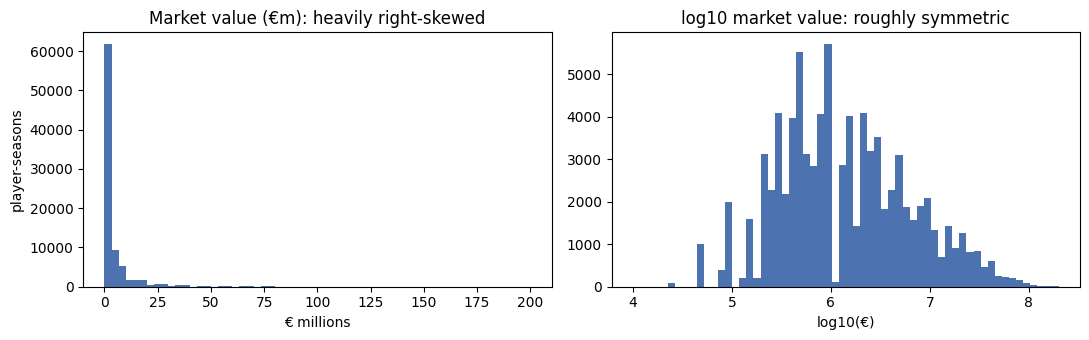

count        85,721.00
mean      4,645,224.39
std      10,352,624.63
min          10,000.00
10%         225,000.00
50%       1,200,000.00
90%      12,000,000.00
99%      50,000,000.00
max     200,000,000.00
Name: market_value_eur, dtype: float64

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(model_df["market_value_eur"] / 1e6, bins=60, color="#4C72B0")
ax[0].set(title="Market value (€m): heavily right-skewed", xlabel="€ millions", ylabel="player-seasons")
ax[1].hist(model_df["log_market_value"], bins=60, color="#4C72B0")
ax[1].set(title="log10 market value: roughly symmetric", xlabel="log10(€)")
plt.tight_layout(); plt.show()
model_df["market_value_eur"].describe(percentiles=[.1, .5, .9, .99])

In [26]:
# Sanity checks: these must all pass before we hand the table to Milestone 3
checks = {
    "one row per player-season": not model_df.duplicated(["player_id", "season"]).any(),
    "target positive": (model_df["market_value_eur"] > 0).all(),
    "valuation not after season end": (model_df["value_date"] <= pd.to_datetime((model_df["season"] + 1).astype(str) + "-06-30")).all(),
    "minutes non-negative": (model_df["minutes_played"] >= 0).all(),
    "league minutes ≤ total": (model_df["league_minutes"] <= model_df["minutes_played"] + 1e-9).all(),
    "age in 15–45": model_df["age"].between(15, 45).all(),
}
pd.Series(checks, name="passed").to_frame()

,passed
one row per player-season,True
target positive,True
valuation not after season end,True
minutes non-negative,True
league minutes ≤ total,True
age in 15–45,True


### Data dictionary

| Column | Type | Meaning |
|---|---|---|
| `player_id`, `name` | id | Transfermarkt player |
| `season` | int | starting year of the season (2019 = 2019/20) |
| `club_id`, `club_name` | id | club where the player played the most minutes that season |
| `domestic_competition_id`, `league` | cat | that club's domestic league |
| **`market_value_eur`** | float | **target:** last valuation on/before 30 June at season end (≤180 days old) |
| `log_market_value` | float | log10 of the target (what we'll actually model) |
| `value_date` | date | date of that valuation |
| `age` | float | age in years on 30 June at season end |
| `position`, `sub_position`, `foot` | cat | from `players` (`foot` missing → `"unknown"`) |
| `height_in_cm` | float | NaN if missing or outside 150–210 |
| `country_of_citizenship` | cat | first listed citizenship |
| `n_apps`, `minutes_played`, `goals`, `assists`, `yellow_cards`, `red_cards` | int | season totals across all tracked competitions |
| `league_*` | int | the same, domestic league only |
| `intl_apps`, `intl_minutes`, `played_europe` | int | UEFA / international club competitions |
| `goals_per90`, `assists_per90`, `minutes_per_app` | float | rates (0 if no minutes) |
| `n_clubs` | int | clubs played for that season (>1 = mid-season transfer) |
| `prev_market_value_eur`, `prev_minutes`, `prev_goals` | float | previous season's values (NaN for a player's first season in the table) |
| `next_market_value_eur`, `log_value_growth` | float | **extension target only, never a feature:** value one year later, and log10(next / current) |

In [27]:
OUT = Path("clean")
OUT.mkdir(exist_ok=True)
model_df.to_csv(OUT / "player_seasons.csv", index=False)
try:
    model_df.to_parquet(OUT / "player_seasons.parquet", index=False)
except ImportError:
    pass
print("saved", OUT / "player_seasons.csv", model_df.shape)

saved clean/player_seasons.csv (85721, 40)


## 6. What we learned, and the refined project question

### What the data contains (key findings)

1. **The tables join cleanly.** Every primary key is unique, and every valuation and appearance matches a player and a game. The only gaps are about 0.6% of appearances whose club isn't in `clubs` (lower-league opponents in cup games) and 20 clubs whose league isn't in `competitions`. Neither affects the core leagues.
2. **The target is valid but irregular.** There are 656k valuations for 41.5k players, updated about every 6 months (median gap 168 days). Only one value was invalid (€0). Values span €10k to €200m with a median of about €1m, so we model them on a **log scale**.
3. **Coverage changed in 2024.** Season 2024 doubled in size because 17 new leagues were added. To keep a consistent population we restrict to the **14 leagues covered every season, 2012–2025**. The 2025/26 season is complete in these leagues (the data runs to 28 June 2026), so it can serve as the test season.
4. **The snapshot tables can't be used as historical features.** `clubs.total_market_value` is 100% empty, and `players.current_club_*`, `international_caps` and `highest_market_value_in_eur` describe the player *today*. Using them for a 2015 row would leak the future, so we built club and league features from where the player actually played each season.
5. **League is a big part of the story.** The median player-season is worth €8m in the Premier League, about €3m in the other big-four leagues, and €0.35–0.9m in the other nine. Position matters less at the median (goalkeepers €0.8m, midfielders €1.3m).
6. **Last season's value is almost the answer.** The correlation between log value and last season's log value is about 0.90. Including it in the model changes what question is being answered (see below).
7. **Final table:** **85,718 player-seasons, 24,773 players, 451 clubs, seasons 2012–2025** (5.4k–6.8k rows per season). Missingness is small apart from fields that are missing by design: previous-season values (a player's first season) and next-season values (the final season, plus players who leave the tracked leagues).


### Project question (refined)

> **For players who appear in the major European competitions Transfermarkt tracks, how accurately can a player's end-of-season market value (log scale) be predicted from that season's playing record, age, position, physical attributes and league? Which of these factors explain most of the value?**

Stated precisely:

| | |
|---|---|
| **Unit** | player-season (one row per player per season), seasons 2012/13–2025/26 |
| **Target** | `log10(market_value_eur)`: last Transfermarkt valuation on or before 30 June at season end |
| **Features** | season performance (minutes, goals, assists, per-90 rates, cards, European minutes); age, position, foot, height; league; optionally previous-season value |
| **Population** | players with ≥1 appearance in a tracked competition that season and a valuation ≤180 days before season end |
| **Validation** | **time-based split:** train on 2012–2023, validate on 2024, test on 2025. A random split would put the same player's other seasons in both train and test. |
| **Metric** | RMSE / MAE on log value (≈ a multiplicative error), plus R²; median absolute % error in € for interpretability |

**How this changes the proposal's three questions:**

1. *"How accurately can a model predict value?"* → answerable as stated, now with a fixed target date, a fixed unit and an honest time-based test set.
2. *"Which factors matter most?"* → answerable through feature importance and coefficients. But **club prestige is hard to measure fairly**: the club fields in the data are today's snapshot, so we use league and European participation as historical stand-ins.
3. *"Who is under- or overvalued?"* → we'll treat this as residual analysis on the test season. The value is a crowd estimate, so a large residual means "valued differently from players with similar stats", not "mispriced".

### Extensions the data can support

* **Future value growth.** The table already has `next_market_value_eur` and `log_value_growth = log10(next / current)` for seasons 2012–2024. The question becomes: *given a player's season, can we predict the change in his value over the next year better than "no change"?* "No change" is a strong baseline: in 14% of player-seasons the value doesn't move at all, and the median change is −10%. **Caution:** next-season value is missing for about 20% of rows (players who leave the tracked leagues or retire). That isn't random, so it has to be discussed in M3. These two columns must never be used as features for the main question.
* **Affordable alternatives.** No new data is needed. For a target player, find players with **similar performance profiles** (same position; nearest neighbours on per-90 stats, minutes, age and league) whose **actual value is well below the model's prediction**. This builds on residual question 3. `transfers.csv` (175k moves, about 10% with a positive fee) could later add a check against real fees.

**Known limitations to carry forward:** the target is a crowd-sourced estimate, not a fee; coverage is mostly top European leagues; goals and assists favour attackers, so position should interact with stats (or we model positions separately); goalkeepers and defenders have few performance stats in this data (no tackles, saves or passes); appearances cover only the competitions the scraper follows, so minutes in untracked cups or friendlies are missing.